In [207]:
import numpy as np
from pathlib import Path
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import r2_score
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import ElasticNetCV, LassoCV, RidgeCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from patsy import dmatrices

In [216]:
DATA_PATH = Path("ApartmentPricePredict") / "apartments_for_sale.csv"
df = pd.read_csv(DATA_PATH)
df.head(10)

,construction_type,new_construction,elevator,floors_in_the_building,floor_area,number_of_rooms,number_of_bathrooms,ceiling_height,floor,balcony,furniture,renovation,address,price,currency,datetime,reg_id
0,NaN,0.0,0.0,-1.0,NaN,0.0,0.0,0.0,0.0,NaN,NaN,NaN,"Lernagorts Street, Vardenis",80000 monthly,AMD,2022-11-25,7
1,Stone,0.0,0.0,5.0,75.0,3.0,1.0,2.8,3.0,Open balcony,NaN,Old Renovation,Gegharkunik › Gavar,19000,USD,2022-11-25,7
2,Panels,0.0,0.0,5.0,47.0,1.0,1.0,3.0,2.0,Open balcony,NaN,No Renovation,Kotayk › Hankavan,4500,USD,2022-11-25,4
3,Panels,0.0,1.0,9.0,68.0,2.0,1.0,2.5,6.0,Open balcony,NaN,Old Renovation,Kotayk › Hrazdan,17500,USD,2022-11-25,4
4,Stone,0.0,0.0,5.0,95.0,2.0,1.0,2.8,1.0,Closed balcony,NaN,Old Renovation,Kotayk › Abovian,100000,USD,2022-11-25,4
5,Panels,0.0,1.0,9.0,53.0,2.0,1.0,2.7,3.0,Closed balcony,By agreement,Cosmetic Renovation,Kotayk › Abovian,44000,USD,2022-12-15,4
6,Stone,0.0,0.0,5.0,76.0,3.0,1.0,2.7,3.0,Closed balcony,Not available,Old Renovation,Kotayk › Abovian,62000,USD,2022-12-15,4
7,Panels,0.0,0.0,2.0,76.0,3.0,1.0,3.0,2.0,Open balcony,NaN,No Renovation,"Arabkir street, Kasakh",42000,USD,2022-12-15,4
8,Stone,0.0,0.0,5.0,85.0,3.0,1.0,2.7,5.0,Not available,Not available,Old Renovation,Lorri › Vanadzor,5303475,AMD,2022-12-15,6
9,Bricks,0.0,0.0,5.0,72.0,3.0,1.0,2.5,1.0,Open balcony,Available,Old Renovation,Shirak › Gyumri,32000,USD,2022-12-15,5


In [209]:
df['construction_type'].value_counts()
df = df.dropna(subset=['price']).copy()

fill_values = {
    'elevator': df['elevator'].mode()[0],                    
    'construction_type': df['construction_type'].mode()[0],
    'floor': df['floor'].mode()[0],
    'floors_in_the_building': df['floors_in_the_building'].mode()[0],
    'balcony': df['balcony'].mode()[0],
    'renovation': df['renovation'].mode()[0],
    'number_of_bathrooms': df['number_of_bathrooms'].median(),
    'floor_area': df['floor_area'].median(),
}
df = df.fillna(value=fill_values)

In [210]:
df = df[~df.price.astype(str).str.contains("monthly", na=False)]
df = df[~df.price.astype(str).str.contains("daily", na=False)]

df['price'] = pd.to_numeric(df.price)

In [211]:
#converting all the prices to usd by 2022 rate
currency_rate = {"USD":1, 'AMD':1/400, "RUB":1/65, 'EUR':1.05}
df['price_usd'] = df.price * df.currency.map(currency_rate)

In [212]:
# merging the rare construction types into one 'other' category
rare = ['Cassette', 'Bricks', 'Wooden']
df['construction_type'] = df['construction_type'].replace(rare, "Other")
df['furniture'].fillna("Unknown", inplace=True)
# dropping 4 rows dont contain any info about their renovation
df = df[df['renovation'] != "Open balcony"]
df['floors_in_the_building'] = np.abs(df['floors_in_the_building'])
df

,construction_type,new_construction,elevator,floors_in_the_building,floor_area,number_of_rooms,number_of_bathrooms,ceiling_height,floor,balcony,furniture,renovation,address,price,currency,datetime,reg_id,price_usd
1,Stone,0.0,0.0,5.0,75.0,3.0,1.0,2.80,3.0,Open balcony,Unknown,Old Renovation,Gegharkunik › Gavar,19000,USD,2022-11-25,7,19000.0
2,Panels,0.0,0.0,5.0,47.0,1.0,1.0,3.00,2.0,Open balcony,Unknown,No Renovation,Kotayk › Hankavan,4500,USD,2022-11-25,4,4500.0
3,Panels,0.0,1.0,9.0,68.0,2.0,1.0,2.50,6.0,Open balcony,Unknown,Old Renovation,Kotayk › Hrazdan,17500,USD,2022-11-25,4,17500.0
4,Stone,0.0,0.0,5.0,95.0,2.0,1.0,2.80,1.0,Closed balcony,Unknown,Old Renovation,Kotayk › Abovian,100000,USD,2022-11-25,4,100000.0
5,Panels,0.0,1.0,9.0,53.0,2.0,1.0,2.70,3.0,Closed balcony,By agreement,Cosmetic Renovation,Kotayk › Abovian,44000,USD,2022-12-15,4,44000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31349,Panels,0.0,1.0,14.0,96.0,3.0,1.0,2.80,5.0,Not available,Available,Major Renovation,"Zoravar Andranik street, Yerevan",124000,USD,2022-12-15,1,124000.0
31350,Panels,0.0,1.0,9.0,75.0,3.0,1.0,2.75,2.0,Closed balcony,Not available,Major Renovation,"Zoravar Andranik street, Yerevan",89000,USD,2022-12-15,1,89000.0
31351,Monolith,1.0,1.0,18.0,102.0,3.0,1.0,2.80,7.0,Open balcony,Available,Major Renovation,"Orbeli Brothers street, Yerevan",225000,USD,2022-12-15,1,225000.0
31352,Monolith,1.0,1.0,15.0,75.0,3.0,2.0,2.80,11.0,Not available,Available,Major Renovation,"Davtashen 1st Block 1, Yerevan",180000,USD,2022-12-15,1,180000.0


In [213]:
#dropping unneeded columns
df.drop(['datetime', 'address', 'price', 'currency'], axis=1, inplace=True)

In [214]:
# data is highly skewed, therefore I am going to do a logarithmic transformation for pricing and floor area
# For this project, just because my curiosity, I will use 2 different approaches for handling the pricing prediction

In [215]:
print(df.columns)
df['reg_id'].value_counts()

Index(['construction_type', 'new_construction', 'elevator',
       'floors_in_the_building', 'floor_area', 'number_of_rooms',
       'number_of_bathrooms', 'ceiling_height', 'floor', 'balcony',
       'furniture', 'renovation', 'reg_id', 'price_usd'],
      dtype='object')


reg_id
1     28243
4       800
2       506
6       410
5       395
3       236
7       170
8       170
10      129
11      102
9        67
12       63
13       56
Name: count, dtype: int64

In [65]:
price_model = smf.ols('np.log(price_usd) ~ construction_type + new_construction + construction_type:new_construction +\
elevator + floors_in_the_building + np.log(floor_area) + number_of_bathrooms + \
ceiling_height + C(balcony) + renovation + floor + number_of_rooms + C(reg_id) \
+ renovation:floor_area + furniture', data=df).fit(cov_type="HC3")
print(price_model.summary())

                            OLS Regression Results                            
Dep. Variable:      np.log(price_usd)   R-squared:                       0.559
Model:                            OLS   Adj. R-squared:                  0.559
Method:                 Least Squares   F-statistic:                     823.5
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        00:24:38   Log-Likelihood:                -26354.
No. Observations:               31347   AIC:                         5.280e+04
Df Residuals:                   31300   BIC:                         5.319e+04
Df Model:                          46                                         
Covariance Type:                  HC3                                         
                                                   coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

In [66]:
# the models r^2 values is bigger than 0.5, which is quite good, so I will try to detect and remove influential outliers
# then Check Variance Inflation Factors (VIF) for Multicollinearity
# after which 

In [67]:


# getting cook's distance from out dataset (measures how much all of your model's predictions would shift if a single data point were deleted.)
influence = price_model.get_influence()
cooks_d = influence.cooks_distance[0]

# defining standard threshold (4 / N)
threshold = 4 / len(df)

# filtering out rows exceeding the threshold
outlier_mask = cooks_d > threshold
df_clean = df[~outlier_mask].copy()
df_clean["is_first"] = (df_clean["floor"] == 1).astype(int)
df_clean["is_last"]  = (df_clean["floor"] == df_clean["floors_in_the_building"]).astype(int)
print(df_clean['reg_id'].value_counts())
df_clean['renovation'] = df_clean['renovation'].replace({
    'Partial Renovation': 'No Renovation / Minor',
    'Old Renovation': 'No Renovation / Minor', "No Renovation":"No Renovation / Minor"
})
df_clean['reg_id'] = df_clean['reg_id'].astype(str)
df_clean['reg_id'] = df_clean['reg_id'].replace({"9":"Other", "10":"Other", '11':'Other', '12':'Other', '13':'Other'})
df_clean['floors_in_the_building'] = df_clean['floors_in_the_building'].astype(int)
print(df_clean['renovation'].value_counts())

df_clean

reg_id
1     27911
4       742
2       463
6       346
5       343
3       200
8       132
7       109
10       88
11       68
12       41
13       16
9        14
Name: count, dtype: int64
renovation
Major Renovation         11201
No Renovation / Minor     9838
Euro Renovation           3923
Cosmetic Renovation       3222
Designer Renovation       2289
Name: count, dtype: int64


,construction_type,new_construction,elevator,floors_in_the_building,floor_area,number_of_rooms,number_of_bathrooms,ceiling_height,floor,balcony,furniture,renovation,reg_id,price_usd,is_first,is_last
1,Stone,0.0,0.0,5,75.0,3.0,1.0,2.80,3.0,Open balcony,Unknown,No Renovation / Minor,7,19000.0,0,0
3,Panels,0.0,1.0,9,68.0,2.0,1.0,2.50,6.0,Open balcony,Unknown,No Renovation / Minor,4,17500.0,0,0
4,Stone,0.0,0.0,5,95.0,2.0,1.0,2.80,1.0,Closed balcony,Unknown,No Renovation / Minor,4,100000.0,1,0
5,Panels,0.0,1.0,9,53.0,2.0,1.0,2.70,3.0,Closed balcony,By agreement,Cosmetic Renovation,4,44000.0,0,0
6,Stone,0.0,0.0,5,76.0,3.0,1.0,2.70,3.0,Closed balcony,Not available,No Renovation / Minor,4,62000.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31349,Panels,0.0,1.0,14,96.0,3.0,1.0,2.80,5.0,Not available,Available,Major Renovation,1,124000.0,0,0
31350,Panels,0.0,1.0,9,75.0,3.0,1.0,2.75,2.0,Closed balcony,Not available,Major Renovation,1,89000.0,0,0
31351,Monolith,1.0,1.0,18,102.0,3.0,1.0,2.80,7.0,Open balcony,Available,Major Renovation,1,225000.0,0,0
31352,Monolith,1.0,1.0,15,75.0,3.0,2.0,2.80,11.0,Not available,Available,Major Renovation,1,180000.0,0,0


In [68]:
formula = (
    'np.log(price_usd) ~ C(construction_type) + C(new_construction) + C(construction_type):C(new_construction) +\
C(elevator) + np.log(floor_area) + number_of_bathrooms + \
ceiling_height + C(balcony) + C(renovation) + number_of_rooms + C(reg_id) + C(is_first) + C(is_last) + floors_in_the_building' 
)
y, X = dmatrices(formula, data=df_clean, return_type="dataframe")

vif_df = pd.DataFrame()
vif_df["variable"] = X.columns
vif_df["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# Display variables with VIF > 5 or 10 (high multicollinearity)
print(vif_df[vif_df["VIF"] > 5].sort_values("VIF", ascending=False))

                         variable        VIF
3   C(construction_type)[T.Stone]  11.159085
2  C(construction_type)[T.Panels]   9.385996
4      C(new_construction)[T.1.0]   8.253574


In [69]:
train_df, test_df = train_test_split(df_clean, test_size=0.2, random_state=14)
ols_model = smf.ols(formula, data=train_df).fit(cov_type="HC3")

In [70]:
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:      np.log(price_usd)   R-squared:                       0.771
Model:                            OLS   Adj. R-squared:                  0.770
Method:                 Least Squares   F-statistic:                     2500.
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        00:24:49   Log-Likelihood:                -7560.0
No. Observations:               24378   AIC:                         1.518e+04
Df Residuals:                   24347   BIC:                         1.543e+04
Df Model:                          30                                         
Covariance Type:                  HC3                                         
                                                                coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------

In [201]:
predict_ols = ols_model.predict(test_df)
ols_test_r2 = r2_score(np.log(test_df['price_usd']), predict_ols)
print(ols_test_r2)

0.7733135899182676


0.6303610941082016


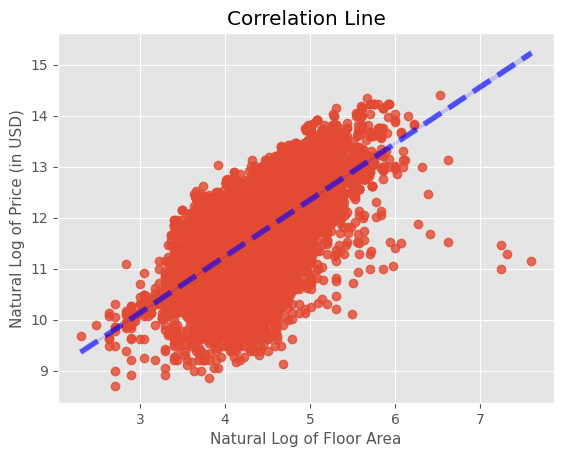

In [72]:
df_plot = np.log(df_clean[['price_usd', 'floor_area']])
plt.style.use('ggplot')
sns.regplot(y='price_usd', x='floor_area', data=df_plot, line_kws={"color": "blue", "lw": 4, "ls": "--", "alpha": 0.6})
plt.xlabel('Natural Log of Floor Area', fontsize=11)
plt.ylabel('Natural Log of Price (in USD)', fontsize=11)
plt.title("Correlation Line")
print(df_plot['floor_area'].corr(df_plot['price_usd']))

In [73]:
# this is this the universal model, which can be used for predicting the housing prices in means of 2022, now I will use RidgeCV regression for tuning my hyperparamteres 

In [171]:
# 1. Transform variables and drop old columns
df_clean_reg = df_clean.copy()
df_clean_reg['log_price'] = np.log(df_clean_reg['price_usd'])
df_clean_reg['log_floor_area'] = np.log(df_clean_reg['floor_area'])
df_clean_reg.drop(['price_usd', 'floor_area', 'furniture'], axis=1, inplace=True)

# 2. Define feature groups (Removed 'log_price' from numer)
kittie = ['construction_type', 'new_construction', 'elevator', 'balcony', 'reg_id', 'is_first', 'is_last', 'renovation']
numer = ['floors_in_the_building', 'floor', 'number_of_rooms', 'number_of_bathrooms', 'log_floor_area', 'ceiling_height']

# 3. One-hot encode categoricals on the full dataset
dff = pd.get_dummies(df_clean_reg, columns=kittie, drop_first=True, dtype=float)

# 4. Separate features (X) and target (y)
X = dff.drop(['log_price'], axis=1)
y = dff['log_price']

# 5. Split dataset FIRST to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=14)

# Copy to avoid pandas SettingWithCopyWarning
X_train = X_train.copy()
X_test = X_test.copy()

# 6. Standardize continuous numerical features
scaler = StandardScaler()
X_train[numer] = scaler.fit_transform(X_train[numer])
X_test[numer] = scaler.transform(X_test[numer])       

In [172]:
alphas = np.logspace(-3, 3, 100)

ridge_cv = RidgeCV(
    alphas=alphas, 
    cv=5,                
    scoring='r2'         
)

ridge_cv.fit(X_train, y_train)

ridge_score_train = ridge_cv.score(X_train, y_train)
ridge_score_test = ridge_cv.score(X_test, y_test)
print(f"Optimal Alpha: {ridge_cv.alpha_:.4f}")
print(f"Train R^2 Score: {ridge_score_train:.4f}")
print(f"Test R^2 Score:  {ridge_score_test:.4f}")


Optimal Alpha: 0.3054
Train R^2 Score: 0.7687
Test R^2 Score:  0.7709


In [173]:
print(ridge_cv.coef_)
predict_ridge = ridge_cv.predict(X_test)

[ 0.02160309 -0.05079577  0.04166448  0.10097422 -0.00808997  0.34991255
 -0.18992939 -0.25193109 -0.05173586  0.02164643  0.08227775  0.02099248
  0.08739671  0.11432484 -0.71646711 -0.800703   -0.71709155 -1.14291661
 -1.30302554 -1.31400056 -1.12352963 -0.91606582 -0.14997203 -0.08788628
  0.31847416  0.12912226  0.18478179 -0.06781367]


In [174]:
# lasso model 
alpha_range = np.logspace(-4, 2, 100)
lasso_cv = LassoCV(
    alphas=alpha_range,
    random_state=14,
    max_iter=10000)

lasso_cv.fit(X_train, y_train)
lasso_score_train = lasso_cv.score(X_train, y_train)
lasso_score_test = lasso_cv.score(X_test, y_test)

print(f"Optimal Alpha: {lasso_cv.alpha_:.4f}")
print(f"Train R^2 Score: {lasso_score_train:.4f}")
print(f"Test R^2 Score:  {lasso_score_test:.4f}")


Optimal Alpha: 0.0001
Train R^2 Score: 0.7687
Test R^2 Score:  0.7708


In [175]:
print("The coefficients of lasso regression result: \n", lasso_cv.coef_)
predict_lasso = lasso_cv.predict(X_test)

The coefficients of lasso regression result: 
 [ 0.02224881 -0.05055629  0.04174943  0.10157193 -0.00769873  0.34995471
 -0.16834996 -0.24838284 -0.04672921  0.02378863  0.08409197  0.01918578
  0.08619705  0.11311044 -0.70878003 -0.78462554 -0.71250027 -1.13275704
 -1.29355743 -1.28749209 -1.10231693 -0.90297301 -0.14936633 -0.08792374
  0.31628206  0.12704992  0.18363426 -0.06916871]


In [176]:
alpha_ranges = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]

elastic_cv = ElasticNetCV(l1_ratio=alpha_ranges, random_state=14, max_iter=20000, n_jobs=-1)
elastic_cv.fit(X_train, y_train)

elastic_score_train = elastic_cv.score(X_train, y_train)
elastic_score_test = elastic_cv.score(X_test, y_test)
print(f"Optimal Alpha: {elastic_cv.alpha_:.4f}")
print(f"Train R^2 Score: {elastic_score_train:.4f}")
print(f"Test R^2 Score:  {elastic_score_test:.4f}")


Optimal Alpha: 0.0004
Train R^2 Score: 0.7680
Test R^2 Score:  0.7700


In [177]:
print("The coefficients of Elastic Net results: \n ",elastic_cv.coef_)
predict_elastic = elastic_cv.predict(X_test)

The coefficients of Elastic Net results: 
  [ 0.02467671 -0.04987501  0.04205869  0.10380706 -0.00638101  0.3502764
 -0.09267135 -0.23545703 -0.02858987  0.03131127  0.09096519  0.012982
  0.08226088  0.10891941 -0.67980884 -0.72397793 -0.69506807 -1.09271552
 -1.2552238  -1.17962098 -1.01845621 -0.85244617 -0.14757179 -0.08824352
  0.30892618  0.12008292  0.1799653  -0.07386512]


In [190]:
tree_reg = DecisionTreeRegressor(random_state=14)
param_grid = {
    'max_depth':[x for x in range(1, 21)],
    'min_samples_leaf': [x for x in range(1, 21)]}

tree_grid = RandomizedSearchCV(
    n_iter = 64,
    param_distributions=param_grid,
    estimator=tree_reg,
    scoring='r2',
    cv=5,
    n_jobs = -1,
    random_state=14
)

tree_grid.fit(X_train, y_train)

# 6. Evaluate the optimized model
best_tree = tree_grid.best_estimator_
train_score = best_tree.score(X_train, y_train)
tree_reg_test_score = best_tree.score(X_test, y_test)

print(f"Optimized Train R^2: {train_score:.4f}")
print(f"Optimized Test R^2: {tree_reg_test_score:.4f}")


Optimized Train R^2: 0.8408
Optimized Test R^2: 0.7544


In [179]:
print(f"Best Parameters: {tree_grid.best_params_}")
predict_tree = best_tree.predict(X_test)

Best Parameters: {'max_depth': 17, 'min_samples_leaf': 4}


In [180]:
from sklearn.ensemble import RandomForestRegressor

# Initialize a Random Forest
# n_estimators=100 means it will train 100 trees simultaneously and average them


forest_reg = RandomForestRegressor(random_state=14)

param_grid_for = {
    'n_estimators': [50, 100, 200,],          # Number of trees
    'max_depth': [x for x in range(1, 21)],          # Maximum depth of trees
    'max_features': [1.0, 'sqrt', 0.5],       # Features to consider per split
    'min_samples_split': [2, 5, 7, 8,  9, 10, 12],          # Min samples to split a node
    'min_samples_leaf': [x for x in range(1, 14)],            # Min samples at leaf node
    'bootstrap': [True, False]                # Bootstrap sampling
}

gridd = RandomizedSearchCV(
    n_iter = 64,
    param_distributions=param_grid_for,
    estimator=forest_reg,
    scoring='r2',
    cv=5,
    n_jobs = -1,
    random_state=14
)

# Fit the ensemble model
gridd.fit(X_train, y_train)

# Evaluate the new scores
best_forest_reg = gridd.best_estimator_
forest_train_score = best_forest_reg.score(X_train, y_train)
forest_test_score = best_forest_reg.score(X_test, y_test)

print(f"Random Forest Train R^2: {forest_train_score:.4f}")
print(f"Random Forest Test R^2: {forest_test_score:.4f}")

Random Forest Train R^2: 0.9175
Random Forest Test R^2: 0.8277


In [181]:
print(f"Best Parameters: {gridd.best_estimator_}")
predict_forest = best_forest_reg.predict(X_test)

Best Parameters: RandomForestRegressor(bootstrap=False, max_depth=20, max_features=0.5,
                      min_samples_split=12, n_estimators=200, random_state=14)


In [182]:
knn_reg = KNeighborsRegressor()

param_grid_knn = {
        "n_neighbors":[x for x in range(1, 21)],
        'weights':['uniform', 'distance'],
        'metric':['euclidean', 'manhattan', 'minkowski'],
    'p':[1, 2] 
}

knn_grid = RandomizedSearchCV(
    n_iter = 64,
    estimator = knn_reg,
    param_distributions = param_grid_knn,
    scoring="r2",
    cv=5,
    n_jobs = -1,
    random_state=14
)

knn_grid.fit(X_train, y_train)


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsRegressor()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'metric': ['euclidean', 'manhattan', ...], 'n_neighbors': [1, 2, ...], 'p': [1, 2], 'weights': ['uniform', 'distance']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",64
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 

In [183]:
best_knn_reg = knn_grid.best_estimator_
knn_score_train = best_knn_reg.score(X_train, y_train)
knn_score_test = best_knn_reg.score(X_test, y_test)

print(f"KNN Regressor Train R^2 {knn_score_train:.4f}")
print(f"KNN Regressor Test R^2 {knn_score_test:.4f}")

KNN Regressor Train R^2 0.9949
KNN Regressor Test R^2 0.7056


In [184]:
print(f"The best parameters for KNN Regressor: {knn_grid.best_params_}")
predict_knn = best_knn_reg.predict(X_test)

The best parameters for KNN Regressor: {'weights': 'distance', 'p': 2, 'n_neighbors': 9, 'metric': 'manhattan'}


In [185]:
names = ['OLS Model', 'Ridge CV', 'Lasso CV', 'Elastic Net CV', 'Decision Tree Regressor', 'Random Forest Regressor', "KNN Regressor"]
scores = [ols_test_r2, ridge_score_test, lasso_score_test, elastic_score_test, decision_tree_reg_test_score, forest_test_score, knn_score_test]
dictt = dict(zip(names, scores))

best_model = max(dictt, key=dictt.get)
worst_model = min(dictt, key=dictt.get)
print("The winner with the best r^2 results is", best_model, f', with score of {max(scores):.4f}!')
print("The loser with the worst r^2 results is", worst_model, f', with score of {min(scores):.4f}!')

The winner with the best r^2 results is Random Forest Regressor , with score of 0.8277!
The loser with the worst r^2 results is KNN Regressor , with score of 0.7056!


In [186]:
print(f"The mean of all scores is {np.mean(scores)}.")
print(f'The standard deviation of all scores is {np.std(scores)}.')

The mean of all scores is 0.7674861051350564.
The standard deviation of all scores is 0.03315927675404033.


In [187]:
predictions = [predict_ols, predict_ridge, predict_lasso, predict_elastic, predict_tree, predict_forest, predict_knn]

In [192]:
def median_absolute_percentage_error(y_test, prediction):
    ape = []
    y_true = np.array(y_test)
    for pred in prediction:
        ape_i = np.median(np.abs((np.exp(y_true) - np.exp(np.array(pred))) / np.exp(y_true)))
        ape.append(ape_i)
    return ape

mdape = median_absolute_percentage_error(y_test, predictions)
ind = 0
for i in mdape:
    print(f"{names[ind]}: {float(i):.4f}")
    ind += 1

OLS Model: 0.2165
Ridge CV: 0.2160
Lasso CV: 0.2152
Elastic Net CV: 0.2138
Decision Tree Regressor: 0.1834
Random Forest Regressor: 0.1625
KNN Regressor: 0.1683


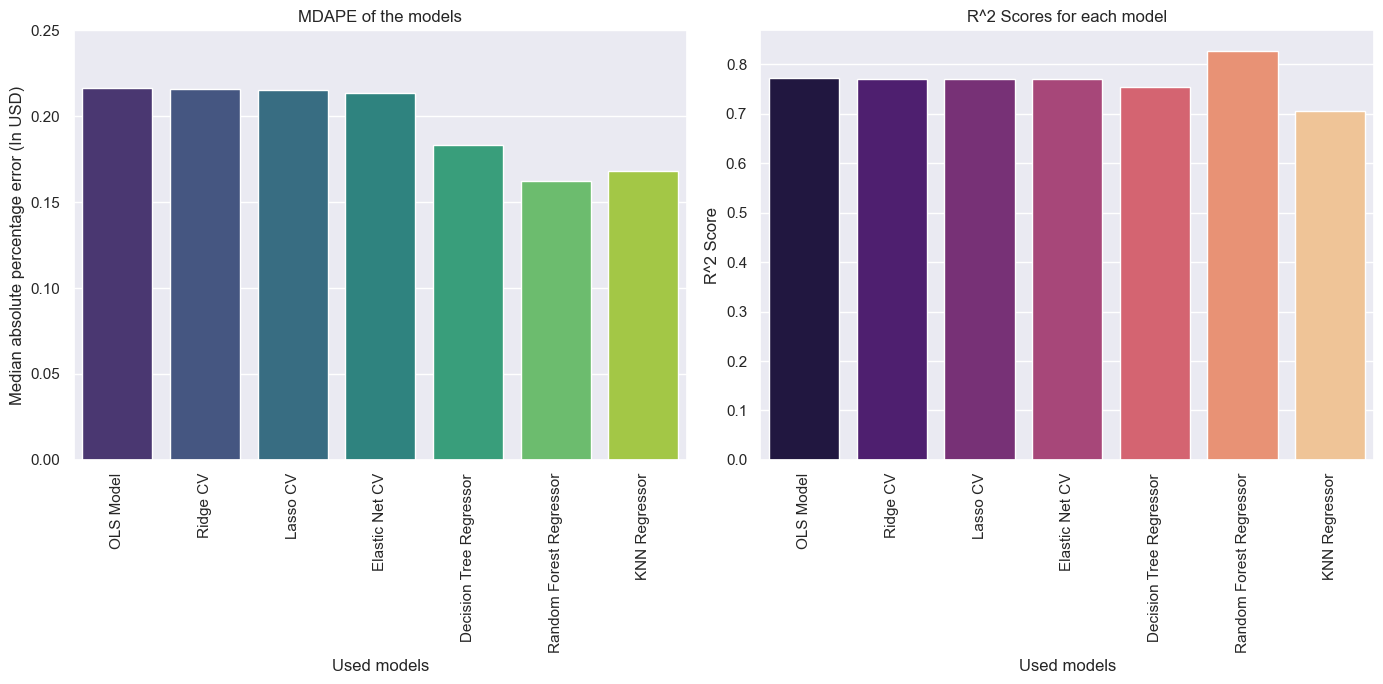

In [200]:
fig, ax = plt.subplots(1, 2, figsize=(14, 7), sharex=True)
sns.set_style('darkgrid')

# First plot (Use barplot instead of catplot)
sns.barplot(x=names, y=mdape, ax=ax[0], hue=names, palette="viridis", legend=False)
ax[0].tick_params(axis='x', rotation=90)
ax[0].set_xlabel('Used models')
ax[0].set_ylabel("Median absolute percentage error (In USD)")
ax[0].set_ylim(0, 0.25) 
ax[0].set_title("MDAPE of the models") 

# Second plot
sns.barplot(x=names, y=scores, ax=ax[1], hue=names, palette='magma', legend=False)
ax[1].tick_params(axis='x', rotation=90)
ax[1].set_xlabel('Used models')
ax[1].set_ylabel("R^2 Score")
ax[1].set_title("R^2 Scores for each model")
plt.tight_layout()
plt.show()

In [ ]:
# as we clearly see, the R^2 and MDAPE values are identical for linear models, however, we also notice that
# MDAPE value for KNN Regressor is the second lowest, which means it truly predicted huge part of values
# however, the present outliers of the data penalize the R^2 of KNN Regressor a lot, that is why its R^2 is the lowest